<a href="https://colab.research.google.com/github/renatobdo/doutorado/blob/main/03_analise_causas_associadas_sim_2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Título e objetivo

# Análise das causas associadas aos óbitos por dengue no SIM

Este notebook analisa as causas e condições mencionadas nas declarações de
óbito cuja causa básica foi dengue em 2023.

As principais etapas são:

1. Carregamento da base normalizada e enriquecida com descrições da CID-10;
2. Verificação da qualidade dos dados;
3. Identificação das causas básicas e das condições associadas;
4. Contagem das menções de cada código CID-10;
5. Contagem dos óbitos distintos em que cada condição foi mencionada;
6. Cálculo dos percentuais em relação ao total de óbitos por dengue;
7. Análise das causas segundo sua posição na Declaração de Óbito;
8. Geração de tabelas resumidas para análises posteriores.

Neste notebook, o termo "causa associada" refere-se às condições registradas
nas linhas A, B, C, D ou na Parte II da Declaração de Óbito, excluindo a
própria causa básica dengue.

2 - Importação das bibliotecas

In [1]:
import os
import pandas as pd


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


3. Definição dos caminhos

In [3]:
BASE_DIR = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag"
)

CAMINHO_ENTRADA = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_causas_cid10.csv"
)

CAMINHO_SAIDA_FREQUENCIAS = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_causas_associadas.csv"
)

CAMINHO_SAIDA_POR_CAMPO = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_causas_por_campo.csv"
)

4. Verificação do arquivo de entrada

In [4]:
if not os.path.exists(CAMINHO_ENTRADA):
    raise FileNotFoundError(
        f"Arquivo de entrada não encontrado: {CAMINHO_ENTRADA}"
    )

print("Arquivo de entrada encontrado.")
print(CAMINHO_ENTRADA)

Arquivo de entrada encontrado.
/content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/sim_obitos_dengue_2023_causas_cid10.csv


5. Carregamento da base normalizada

In [5]:
df_causas = pd.read_csv(
    CAMINHO_ENTRADA,
    encoding="utf-8-sig",
    dtype="string"
)

print("Base carregada com sucesso.")
print(f"Linhas: {len(df_causas):,}")
print(f"Colunas: {df_causas.shape[1]}")

Base carregada com sucesso.
Linhas: 6,266
Colunas: 9


Converta o identificador para inteiro:

In [6]:
df_causas["ID_REGISTRO"] = pd.to_numeric(
    df_causas["ID_REGISTRO"],
    errors="raise"
).astype("int64")

Visualize:

In [7]:
df_causas.head(20)

,ID_REGISTRO,CAMPO_CAUSA,PAPEL_CAUSA,VALOR_ORIGINAL,CODIGO_SIM,CODIGO_CATEGORIA,CODIGO_SUBCATEGORIA,DESCRICAO_CID,NIVEL_MAPEAMENTO
0,1,CAUSABAS,Causa básica,A91,A91,A91,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
1,1,LINHAA,Linha A da Parte I,*R092,R092,R09,R092,Parada respiratória,subcategoria
2,1,LINHAB,Linha B da Parte I,*R402,R402,R40,R402,Coma não especificado,subcategoria
3,1,LINHAC,Linha C da Parte I,*A91X,A91X,A91,A91X,Febre hemorrágica devida ao vírus do dengue,categoria
4,1,LINHAII,Outras condições significativas — Parte II,*E149*I10X,E149,E14,E149,Diabetes mellitus não especificado - sem compl...,subcategoria
5,1,LINHAII,Outras condições significativas — Parte II,*E149*I10X,I10X,I10,I10X,Hipertensão essencial (primária),categoria
6,2,CAUSABAS,Causa básica,A91,A91,A91,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
7,2,LINHAA,Linha A da Parte I,*I490,I490,I49,I490,Flutter e fibrilação ventricular,subcategoria
8,2,LINHAB,Linha B da Parte I,*A419,A419,A41,A419,Septicemia não especificada,subcategoria
9,2,LINHAC,Linha C da Parte I,*N390,N390,N39,N390,Infecção do trato urinário de localização não ...,subcategoria


7. Resumo geral da base

In [8]:
total_obitos = df_causas["ID_REGISTRO"].nunique()
total_mencoes = len(df_causas)
total_codigos = df_causas["CODIGO_SIM"].nunique()

print(f"Óbitos distintos: {total_obitos:,}")
print(f"Menções de CID: {total_mencoes:,}")
print(f"Códigos CID distintos: {total_codigos:,}")

Óbitos distintos: 1,322
Menções de CID: 6,266
Códigos CID distintos: 424


Aqui é importante lembrar:
> Um mesmo óbito pode conter vários códigos CID-10. Por isso, o número de
> menções é maior que o número de óbitos.

8. Conferência das causas básicas

Primeiro, veja quais códigos aparecem como causa básica:

In [9]:
causas_basicas = (
    df_causas[
        df_causas["CAMPO_CAUSA"] == "CAUSABAS"
    ]
    .groupby(
        [
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ],
        dropna=False
    )
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
    .sort_values(
        "total_obitos",
        ascending=False
    )
)

causas_basicas

,CODIGO_SIM,DESCRICAO_CID,total_obitos
0,A90,Dengue [dengue clássico],839
1,A91,Febre hemorrágica devida ao vírus do dengue,483


Validação:

In [10]:
registros_causa_basica_nao_dengue = df_causas[
    (df_causas["CAMPO_CAUSA"] == "CAUSABAS")
    &
    (~df_causas["CODIGO_CATEGORIA"].isin(["A90", "A91"]))
]

print(
    "Causas básicas diferentes de dengue:",
    len(registros_causa_basica_nao_dengue)
)

Causas básicas diferentes de dengue: 0


9. Separação das causas associadas

Agora criamos um DataFrame apenas com as condições associadas.

Excluímos:

a coluna CAUSABAS;
os próprios códigos de dengue A90 e A91.

In [11]:
df_causas_associadas = df_causas[
    (df_causas["CAMPO_CAUSA"] != "CAUSABAS")
    &
    (~df_causas["CODIGO_CATEGORIA"].isin(["A90", "A91"]))
].copy()

Confira:

In [12]:
print(
    f"Menções de causas associadas: "
    f"{len(df_causas_associadas):,}"
)

print(
    f"Óbitos com pelo menos uma causa associada: "
    f"{df_causas_associadas['ID_REGISTRO'].nunique():,}"
)

Menções de causas associadas: 3,585
Óbitos com pelo menos uma causa associada: 1,254


10. Remoção de duplicidades dentro do mesmo óbito

Um mesmo CID pode aparecer mais de uma vez na declaração do mesmo óbito.

Por exemplo:

LINHAA = R571
LINHAB = R571

Para calcular em quantos óbitos determinada condição apareceu, devemos contar esse CID apenas uma vez por óbito:

In [13]:
df_causas_associadas_unicas = (
    df_causas_associadas
    .drop_duplicates(
        subset=[
            "ID_REGISTRO",
            "CODIGO_SIM"
        ]
    )
    .copy()
)

Compare:

In [14]:
print(
    "Menções antes da remoção de duplicidades:",
    len(df_causas_associadas)
)

print(
    "Combinações únicas óbito-CID:",
    len(df_causas_associadas_unicas)
)

Menções antes da remoção de duplicidades: 3585
Combinações únicas óbito-CID: 3573


Interpretação do código da célula anterior:

havia 3.585 menções de códigos CID nas declarações de óbito;
dessas, 12 eram repetições do mesmo código dentro do mesmo óbito.

Ou seja:

3585 - 3573 = 12

Havia apenas 12 linhas duplicadas.

Isso é perfeitamente normal. Significa que, em 12 situações, um mesmo código CID foi registrado mais de uma vez na declaração do mesmo óbito.

11. Frequência das causas associadas

In [14]:
frequencia_causas_associadas = (
    df_causas_associadas_unicas
    .groupby(
        [
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ],
        dropna=False
    )
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
    .sort_values(
        "total_obitos",
        ascending=False
    )
)

Calcule o percentual:

In [15]:
frequencia_causas_associadas["percentual_obitos"] = (
    frequencia_causas_associadas["total_obitos"]
    / total_obitos
    * 100
).round(2)

Visualize as 30 principais:

In [16]:
frequencia_causas_associadas.head(30)

,CODIGO_SIM,DESCRICAO_CID,total_obitos,percentual_obitos
10,A419,Septicemia não especificada,330,24.96
143,I10X,Hipertensão essencial (primária),247,18.68
371,R571,Choque hipovolêmico,189,14.30
325,N179,Insuficiência renal aguda não especificada,154,11.65
236,J189,Pneumonia não especificada,152,11.50
251,J960,Insuficiência respiratória aguda,131,9.91
370,R570,Choque cardiogênico,116,8.77
78,E149,Diabetes mellitus não especificado - sem compl...,89,6.73
189,I509,Insuficiência cardíaca não especificada,88,6.66
372,R578,Outras formas de choque,77,5.82


Interpretação da célula anterior. Por exemplo:

A419 — Septicemia não especificada
330 óbitos
24,96%

Significa:

Septicemia não especificada foi mencionada em 330 dos 1.322 óbitos cuja causa básica foi dengue.

12. Diferença entre menções e óbitos distintos

Também pode ser útil criar uma tabela que mostre as duas medidas:

In [17]:
total_mencoes_por_cid = (
    df_causas_associadas
    .groupby(
        [
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ],
        dropna=False
    )
    .agg(
        total_mencoes=("ID_REGISTRO", "size")
    )
    .reset_index()
)

Junte com a tabela de óbitos distintos:

In [18]:
frequencia_causas_associadas = (
    frequencia_causas_associadas
    .merge(
        total_mencoes_por_cid,
        on=[
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ],
        how="left"
    )
)

Organize:

In [19]:
frequencia_causas_associadas = (
    frequencia_causas_associadas[
        [
            "CODIGO_SIM",
            "DESCRICAO_CID",
            "total_mencoes",
            "total_obitos",
            "percentual_obitos"
        ]
    ]
    .sort_values(
        "total_obitos",
        ascending=False
    )
    .reset_index(drop=True)
)

frequencia_causas_associadas.head(30)

,CODIGO_SIM,DESCRICAO_CID,total_mencoes,total_obitos,percentual_obitos
0,A419,Septicemia não especificada,337,330,24.96
1,I10X,Hipertensão essencial (primária),247,247,18.68
2,R571,Choque hipovolêmico,189,189,14.30
3,N179,Insuficiência renal aguda não especificada,155,154,11.65
4,J189,Pneumonia não especificada,153,152,11.50
5,J960,Insuficiência respiratória aguda,131,131,9.91
6,R570,Choque cardiogênico,116,116,8.77
7,E149,Diabetes mellitus não especificado - sem compl...,90,89,6.73
8,I509,Insuficiência cardíaca não especificada,88,88,6.66
9,R579,Choque não especificado,77,77,5.82


Menções = quantas vezes o código CID foi registrado nos campos das declarações.
Óbitos distintos = em quantos óbitos diferentes aquele CID apareceu, independentemente de quantas vezes foi repetido no mesmo óbito.

Imagine apenas 3 óbitos:
| Óbito | Campo  | CID  |
| ----- | ------ | ---- |
| 1     | LINHAA | R571 |
| 1     | LINHAB | R571 |
| 2     | LINHAA | R571 |
| 3     | LINHAA | A90  |

Se perguntarmos:

Quantas vezes R571 foi mencionado?

A resposta é 3 menções.

Mas se perguntarmos:

Em quantos óbitos R571 apareceu?

A resposta é 2 óbitos.

#Resumo para os itens 13 ao 16


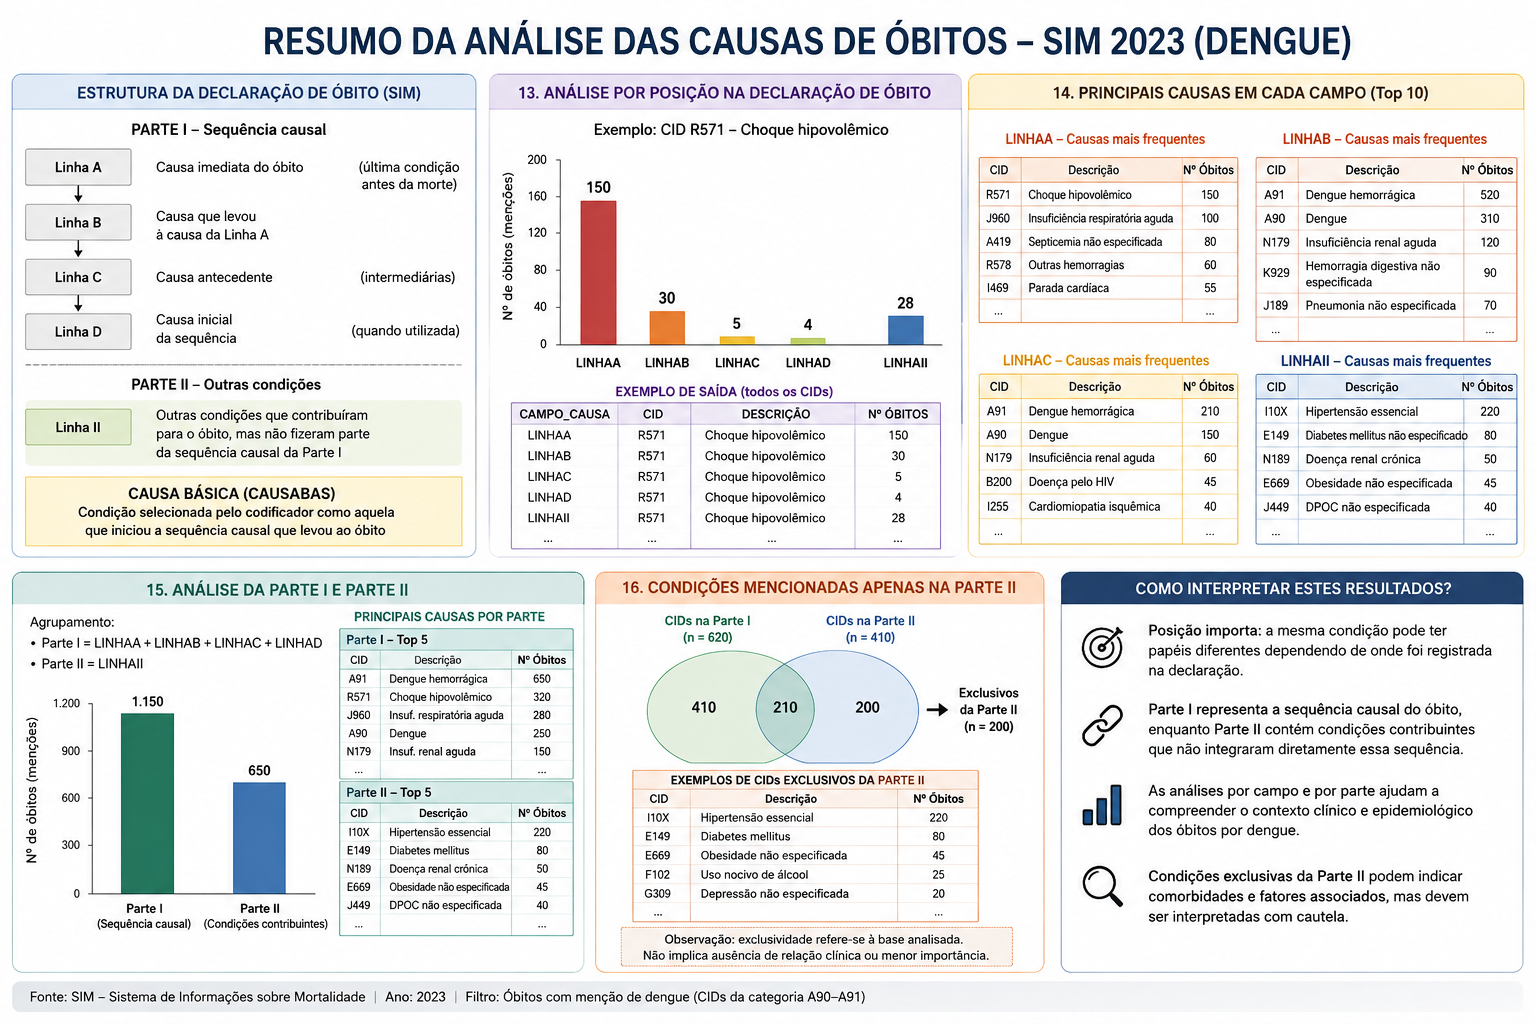

13. Análise por posição na Declaração de Óbito

Agora podemos analisar em que campo cada condição aparece.

In [20]:
frequencia_por_campo = (
    df_causas_associadas
    .groupby(
        [
            "CAMPO_CAUSA",
            "PAPEL_CAUSA",
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ],
        dropna=False
    )
    .agg(
        total_mencoes=("ID_REGISTRO", "size"),
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
    .sort_values(
        [
            "CAMPO_CAUSA",
            "total_obitos"
        ],
        ascending=[True, False]
    )
)

Visualize:

In [21]:
frequencia_por_campo.head(30)

,CAMPO_CAUSA,PAPEL_CAUSA,CODIGO_SIM,DESCRICAO_CID,total_mencoes,total_obitos
4,LINHAA,Linha A da Parte I,A419,Septicemia não especificada,254,254
84,LINHAA,Linha A da Parte I,R571,Choque hipovolêmico,142,142
59,LINHAA,Linha A da Parte I,J960,Insuficiência respiratória aguda,100,100
83,LINHAA,Linha A da Parte I,R570,Choque cardiogênico,94,94
85,LINHAA,Linha A da Parte I,R578,Outras formas de choque,67,67
86,LINHAA,Linha A da Parte I,R579,Choque não especificado,63,63
81,LINHAA,Linha A da Parte I,R092,Parada respiratória,49,49
60,LINHAA,Linha A da Parte I,J969,Insuficiência respiratória não especificada,39,39
89,LINHAA,Linha A da Parte I,R688,Outros sintomas e sinais gerais especificados,26,26
54,LINHAA,Linha A da Parte I,J189,Pneumonia não especificada,23,23


14. Principais causas em cada campo

In [22]:
top_10_por_campo = (
    frequencia_por_campo
    .sort_values(
        [
            "CAMPO_CAUSA",
            "total_obitos"
        ],
        ascending=[True, False]
    )
    .groupby(
        "CAMPO_CAUSA",
        group_keys=False
    )
    .head(10)
)

top_10_por_campo[
    [
        "CAMPO_CAUSA",
        "PAPEL_CAUSA",
        "CODIGO_SIM",
        "DESCRICAO_CID",
        "total_obitos"
    ]
]

,CAMPO_CAUSA,PAPEL_CAUSA,CODIGO_SIM,DESCRICAO_CID,total_obitos
4,LINHAA,Linha A da Parte I,A419,Septicemia não especificada,254
84,LINHAA,Linha A da Parte I,R571,Choque hipovolêmico,142
59,LINHAA,Linha A da Parte I,J960,Insuficiência respiratória aguda,100
83,LINHAA,Linha A da Parte I,R570,Choque cardiogênico,94
85,LINHAA,Linha A da Parte I,R578,Outras formas de choque,67
86,LINHAA,Linha A da Parte I,R579,Choque não especificado,63
81,LINHAA,Linha A da Parte I,R092,Parada respiratória,49
60,LINHAA,Linha A da Parte I,J969,Insuficiência respiratória não especificada,39
89,LINHAA,Linha A da Parte I,R688,Outros sintomas e sinais gerais especificados,26
54,LINHAA,Linha A da Parte I,J189,Pneumonia não especificada,23


Isso permite observar, por exemplo:



*   condições mais frequentes na Linha A;
*   condições mais frequentes na Linha B;
*   comorbidades mais frequentes na Parte II.



15. Análise da Parte I e Parte II

A Parte I representa a cadeia causal que levou ao óbito.

A Parte II contém condições que contribuíram para o óbito, mas não fazem parte diretamente da cadeia causal principal.

Crie uma classificação:

In [23]:
df_causas_associadas["PARTE_DECLARACAO"] = (
    df_causas_associadas["CAMPO_CAUSA"]
    .map({
        "LINHAA": "Parte I",
        "LINHAB": "Parte I",
        "LINHAC": "Parte I",
        "LINHAD": "Parte I",
        "LINHAII": "Parte II"
    })
)

Frequência por parte:

In [24]:
frequencia_por_parte = (
    df_causas_associadas
    .drop_duplicates(
        subset=[
            "ID_REGISTRO",
            "PARTE_DECLARACAO",
            "CODIGO_SIM"
        ]
    )
    .groupby(
        [
            "PARTE_DECLARACAO",
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ],
        dropna=False
    )
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
    .sort_values(
        [
            "PARTE_DECLARACAO",
            "total_obitos"
        ],
        ascending=[True, False]
    )
)

Visualize as principais:

In [25]:
top_20_por_parte = (
    frequencia_por_parte
    .groupby(
        "PARTE_DECLARACAO",
        group_keys=False
    )
    .head(20)
)

top_20_por_parte

,PARTE_DECLARACAO,CODIGO_SIM,DESCRICAO_CID,total_obitos
8,Parte I,A419,Septicemia não especificada,326
226,Parte I,R571,Choque hipovolêmico,189
134,Parte I,J189,Pneumonia não especificada,146
146,Parte I,J960,Insuficiência respiratória aguda,131
225,Parte I,R570,Choque cardiogênico,115
191,Parte I,N179,Insuficiência renal aguda não especificada,107
227,Parte I,R578,Outras formas de choque,77
228,Parte I,R579,Choque não especificado,77
148,Parte I,J969,Insuficiência respiratória não especificada,60
213,Parte I,R092,Parada respiratória,58


16. Condições mencionadas apenas na Parte II

Essa análise pode ajudar a identificar comorbidades:

In [26]:
cids_parte_i = set(
    df_causas_associadas.loc[
        df_causas_associadas["PARTE_DECLARACAO"] == "Parte I",
        "CODIGO_SIM"
    ]
)

cids_parte_ii = set(
    df_causas_associadas.loc[
        df_causas_associadas["PARTE_DECLARACAO"] == "Parte II",
        "CODIGO_SIM"
    ]
)

cids_exclusivos_parte_ii = (
    cids_parte_ii - cids_parte_i
)

Filtre:

In [27]:
condicoes_exclusivas_parte_ii = (
    frequencia_por_parte[
        (frequencia_por_parte["PARTE_DECLARACAO"] == "Parte II")
        &
        (
            frequencia_por_parte["CODIGO_SIM"]
            .isin(cids_exclusivos_parte_ii)
        )
    ]
    .sort_values(
        "total_obitos",
        ascending=False
    )
)

condicoes_exclusivas_parte_ii.head(30)

,PARTE_DECLARACAO,CODIGO_SIM,DESCRICAO_CID,total_obitos
320,Parte II,F172,Transtornos mentais e comportamentais devidos ...,26
366,Parte II,I259,Doença isquêmica crônica do coração não especi...,10
305,Parte II,E668,Outra obesidade,7
362,Parte II,I251,Doença aterosclerótica do coração,7
394,Parte II,I694,Seqüelas de acidente vascular cerebral não esp...,7
451,Parte II,M069,Artrite reumatóide não especificada,7
301,Parte II,E148,Diabetes mellitus não especificado - com compl...,6
363,Parte II,I252,Infarto antigo do miocárdio,6
266,Parte II,B342,Infecção por coronavírus de localização não es...,5
313,Parte II,F03X,Demência não especificada,5


Cuidado: aparecer na Parte II não significa automaticamente que uma condição seja uma comorbidade. Porém, esse campo costuma conter condições contribuintes.

17. Número de causas associadas por óbito

In [28]:
causas_por_obito = (
    df_causas_associadas_unicas
    .groupby("ID_REGISTRO")
    .agg(
        quantidade_causas_associadas=("CODIGO_SIM", "nunique")
    )
    .reset_index()
)

Resumo:

In [29]:
causas_por_obito[
    "quantidade_causas_associadas"
].describe()

,quantidade_causas_associadas
count,1254.000000
mean,2.849282
std,1.408138
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,9.000000


Distribuição:

In [30]:
distribuicao_causas_por_obito = (
    causas_por_obito[
        "quantidade_causas_associadas"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("quantidade_causas_associadas")
    .reset_index(name="total_obitos")
)

distribuicao_causas_por_obito

,quantidade_causas_associadas,total_obitos
0,1,227
1,2,333
2,3,330
3,4,201
4,5,118
5,6,24
6,7,17
7,8,3
8,9,1


18. Óbitos sem causas associadas

Nem todos os registros necessariamente possuem condições adicionais além da dengue.

In [31]:
ids_com_causas_associadas = set(
    df_causas_associadas[
        "ID_REGISTRO"
    ].unique()
)

todos_ids = set(
    df_causas[
        "ID_REGISTRO"
    ].unique()
)

ids_sem_causas_associadas = (
    todos_ids - ids_com_causas_associadas
)

print(
    "Óbitos sem causas associadas:",
    len(ids_sem_causas_associadas)
)

Óbitos sem causas associadas: 68


Percentual:

In [32]:
percentual_sem_associadas = (
    len(ids_sem_causas_associadas)
    / total_obitos
    * 100
)

print(
    f"Percentual sem causas associadas: "
    f"{percentual_sem_associadas:.2f}%"
)

Percentual sem causas associadas: 5.14%


19. Validação dos códigos sem descrição

In [33]:
causas_sem_descricao = (
    df_causas_associadas[
        df_causas_associadas[
            "DESCRICAO_CID"
        ].isna()
    ]
    .groupby("CODIGO_SIM")
    .agg(
        total_mencoes=("ID_REGISTRO", "size"),
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
    .sort_values(
        "total_obitos",
        ascending=False
    )
)

causas_sem_descricao.head(30)

,CODIGO_SIM,total_mencoes,total_obitos
0,U071,4,4
1,U072,1,1
2,U099,1,1


20. Salvamento dos resultados
Frequência geral das causas associadas

In [34]:
frequencia_causas_associadas.to_csv(
    CAMINHO_SAIDA_FREQUENCIAS,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Tabela de causas associadas salva em:\n"
    f"{CAMINHO_SAIDA_FREQUENCIAS}"
)

Tabela de causas associadas salva em:
/content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/sim_obitos_dengue_2023_causas_associadas.csv


Frequências por campo da declaração

In [35]:
frequencia_por_campo.to_csv(
    CAMINHO_SAIDA_POR_CAMPO,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Tabela de causas por campo salva em:\n"
    f"{CAMINHO_SAIDA_POR_CAMPO}"
)

Tabela de causas por campo salva em:
/content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/sim_obitos_dengue_2023_causas_por_campo.csv


21. Resumo final

In [36]:
print("=" * 65)
print("RESUMO DA ANÁLISE DE CAUSAS ASSOCIADAS")
print("=" * 65)

print(f"Total de óbitos por dengue: {total_obitos:,}")
print(
    f"Óbitos com causa associada: "
    f"{df_causas_associadas['ID_REGISTRO'].nunique():,}"
)
print(
    f"Óbitos sem causa associada: "
    f"{len(ids_sem_causas_associadas):,}"
)
print(
    f"Códigos associados distintos: "
    f"{df_causas_associadas['CODIGO_SIM'].nunique():,}"
)
print(
    f"Total de menções associadas: "
    f"{len(df_causas_associadas):,}"
)

print("\nCinco condições mais frequentes:")

display(
    frequencia_causas_associadas[
        [
            "CODIGO_SIM",
            "DESCRICAO_CID",
            "total_obitos",
            "percentual_obitos"
        ]
    ].head(5)
)

RESUMO DA ANÁLISE DE CAUSAS ASSOCIADAS
Total de óbitos por dengue: 1,322
Óbitos com causa associada: 1,254
Óbitos sem causa associada: 68
Códigos associados distintos: 420
Total de menções associadas: 3,585

Cinco condições mais frequentes:


,CODIGO_SIM,DESCRICAO_CID,total_obitos,percentual_obitos
0,A419,Septicemia não especificada,330,24.96
1,I10X,Hipertensão essencial (primária),247,18.68
2,R571,Choque hipovolêmico,189,14.30
3,N179,Insuficiência renal aguda não especificada,154,11.65
4,J189,Pneumonia não especificada,152,11.50


O que são causas associadas?

Imagine uma declaração de óbito.
Exemplo 1

| Campo        | Código                           |
| ------------ | -------------------------------- |
| Causa básica | A90 (Dengue)                     |
| Linha A      | R571 (Choque hipovolêmico)       |
| Linha B      | N179 (Insuficiência renal aguda) |

Nesse óbito existem duas causas associadas.

Exemplo 2:
| Campo        | Código       |
| ------------ | ------------ |
| Causa básica | A90 (Dengue) |
| Linha A      | *(vazia)*    |
| Linha B      | *(vazia)*    |
| Linha C      | *(vazia)*    |

Aqui não existe nenhuma condição adicional.

A única informação registrada é a dengue.
Imagine cinco óbitos
| Óbito | Causa básica | Causas associadas           |
| ----- | ------------ | --------------------------- |
| 1     | Dengue       | Choque, insuficiência renal |
| 2     | Dengue       | Diabetes                    |
| 3     | Dengue       | nenhuma                     |
| 4     | Dengue       | Hipertensão, pneumonia      |
| 5     | Dengue       | nenhuma                     |

Observe que:

os óbitos 1, 2 e 4 possuem causas associadas;
os óbitos 3 e 5 não possuem.

O que essa etapa verifica?

Ela responde:

"Existem óbitos cuja única causa registrada foi a dengue?"

Ou, de forma equivalente:

"Todos os óbitos possuem pelo menos uma causa associada?"

Interpretação da célula anterior:

Dos 1.322 óbitos,
1.254
possuem PELO MENOS uma causa associada registrada.

Óbitos sem causa associada: 68

Isso significa que
68
declarações continham apenas a dengue, sem nenhuma outra condição registrada nos campos de causas associadas.


Códigos associados distintos: 420

Esse número costuma gerar dúvida.

Ele não significa 420 óbitos.

Significa que foram encontrados

420 códigos CID diferentes

entre todas as causas associadas.

Por exemplo:

R571
N179
J960
I10
E119
...

Ao todo existem 420 códigos diferentes.

Isso mostra a diversidade de condições registradas juntamente com a dengue.


Total de menções associadas: 3.585
Esse é o número total de vezes em que um código CID apareceu nas declarações.

Imagine um único óbito:
| Campo    | Código |
| -------- | ------ |
| Linha A  | R571   |
| Linha B  | N179   |
| Parte II | I10    |


Esse único óbito gera
3 menções
Outro óbito pode gerar apenas uma.
Somando todos os óbitos, foram registradas
3.585 menções
de causas associadas.

Uma interpretação interessante

Podemos calcular uma média.

Menções por óbito (todos os óbitos)

3585/1322 ≈ 2,71

Ou seja,

cada declaração possui, em média, aproximadamente 2,7 causas associadas registradas.

Menções apenas entre os óbitos que possuem causas associadas

3585/1254 ≈ 2,86

Ou seja,

considerando apenas os óbitos que apresentam alguma causa associada, cada declaração possui, em média, 2,9 causas associadas.

Esse é um indicador interessante da complexidade clínica registrada nas declarações.



O resumo em linguagem natural

Eu escreveria algo como:

Foram analisados 1.322 óbitos por dengue, dos quais 1.254 (94,9%) apresentaram pelo menos uma causa associada registrada e 68 (5,1%) não continham condições adicionais além da dengue. Entre os óbitos com causas associadas foram identificados 420 códigos CID distintos, totalizando 3.585 menções de condições associadas nas declarações de óbito.

Esse texto resume muito bem os números apresentados.

Uma pequena melhoria no relatório

Eu acrescentaria duas linhas com os percentuais, pois facilitam bastante a interpretação:
=================================================================
RESUMO DA ANÁLISE DE CAUSAS ASSOCIADAS
=================================================================

Total de óbitos por dengue.............: 1.322

Óbitos com causa associada.............: 1.254 (94,9%)

Óbitos sem causa associada.............:    68 (5,1%)

Códigos CID associados distintos.......:   420

Total de menções de causas associadas..: 3.585

Média de menções por óbito.............: 2,71

Média por óbito com associação.........: 2,86

essa versão comunica melhor a qualidade e a riqueza dos dados, pois ajuda o leitor a interpretar os números sem precisar fazer cálculos adicionais.